# 16장 · Function Calling의 실행과 결과 반환

도구 실행을 맡은 프로그램은 인자를 검사하고 함수를 호출한 뒤 결과에 원래 호출 ID를 붙입니다. 모델은 이 ID로 요청과 결과를 짝짓습니다.

15장에서 받은 주말 운영 시간 요청에 실제 조회 결과를 붙입니다. 하나의 호출 요청, 프로그램이 실행한 함수, 모델에 돌려줄 결과를 같은 call_id로 따라가 봅시다.

실행을 확인한 커널은 Python 3.12.15입니다.

Python 3 커널을 선택하고 위에서부터 실행하세요. 과제 셀에 직접 코드를 작성한 뒤 바로 아래에서 풀이를 펼쳐 보세요.


## 도구 이름과 인자를 함수 호출로 변환

명세만 본 모델은 운영 시간을 알 수 없습니다. 읽기 전용 조회 함수 안의 표에서 시간을 꺼내면 비로소 답에 쓸 값이 생깁니다.


### 호출 요청을 실행 함수로 넘기기

<p>이 장의 call에는 get_library_hours, 문자열 인자, call_1이 있습니다. 이름과 인자를 검사해 주말 시간표를 조회하고, 결과에는 바로 이 call_1을 붙여 원래 요청과 연결합니다.</p>


### 셀 01 · get_library_hours()의 반환값

이번 셀에서는 모델 없이 파이썬 함수를 직접 부릅니다.


In [1]:
def get_library_hours(day):
    hours = {"weekday": "09:00~18:00", "weekend": "10:00~16:00"}
    return {"day": day, "hours": hours[day], "source": "수업용 가상 도서관"}

print(get_library_hours("weekend")["hours"])

10:00~16:00


10:00~16:00은 주말 표에서 꺼낸 값입니다. 이 함수는 실제 도서관에 접속하지 않습니다. 허용되지 않은 인자가 들어오는지는 함수를 부르기 전에 검사합니다.


### 읽기 전용 함수 연결

<p>함수는 day를 받아 정해진 시간표에서 값을 읽습니다. 데이터는 가상의 수업 자료입니다. 이 함수를 실행했다는 사실과 실제 기관 운영 시간이 맞는다는 주장은 구분해야 합니다.</p>


### 셀 02 · execute_call()과 결과 직렬화

제공 함수는 요청의 이름과 인자를 검사합니다. 성공했을 때 어떤 값이 output 안에 담기는지 읽으세요.

이번 노트북은 주말 조회 요청을 새로 만들어 call_1이라는 ID를 붙입니다. 15장의 예제 ID는 call_demo_1이었습니다. 이제부터 이 요청에 답하는 결과는 call_1을 그대로 사용해야 합니다.


In [2]:
import json

def execute_call(item):
    if not isinstance(item.get("call_id"), str) or not item["call_id"].strip():
        raise ValueError("call_id 없음 또는 공백: 결과 연결 불가")
    try:
        if item.get("name") != "get_library_hours":
            raise ValueError("허용하지 않은 도구")
        args = json.loads(item["arguments"])
        if not isinstance(args, dict) or set(args) != {"day"}:
            raise ValueError("인자 필드 불일치")
        if args["day"] not in {"weekday", "weekend"}:
            raise ValueError("지원하지 않는 요일 값")
        result = {"ok": True, "data": get_library_hours(args["day"])}
    except (ValueError, TypeError, KeyError):
        result = {"ok": False, "error": "invalid_tool_request"}
    return {"type": "function_call_output", "call_id": item["call_id"],
            "output": json.dumps(result, ensure_ascii=False)}

call = {"type": "function_call", "call_id": "call_1", "name": "get_library_hours", "arguments": '{"day":"weekend"}'}
reply = execute_call(call)
print(json.loads(reply["output"])["data"]["hours"])

10:00~16:00


같은 10:00~16:00이 나오지만 이번 값은 reply의 output에 담긴 JSON 문자열에서 읽었습니다. 모델에 보낼 항목의 type은 function_call_output입니다.


### ID와 인자를 거부하는 방법의 차이

<p>execute_call은 호출 ID가 비어 있으면 ValueError를 일으킵니다. ID가 있어 결과를 연결할 수 있지만 이름이나 day가 잘못됐다면, 호출 ID가 포함된 function_call_output에 invalid_tool_request를 담아 반환합니다.</p>


## function_call_output과 call_id 대응

결과를 돌려주는 쪽은 임의의 새 ID를 붙이지 않습니다. 모델이 보낸 호출 항목의 call_id를 그대로 써야 요청과 결과가 한 쌍이 됩니다.

<!-- lesson-visual visual-id-match -->
**결과를 원래 호출과 짝짓는 값**

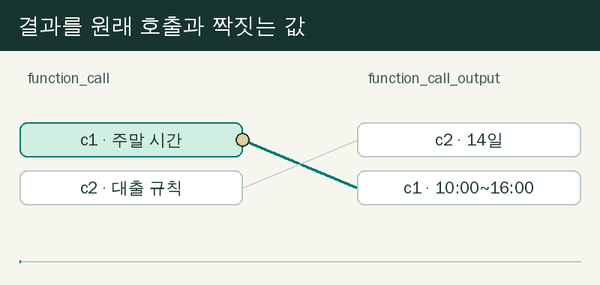

도구의 이름이나 반환 순서 대신 요청과 결과에 공통으로 있는 call_id를 따라갑니다. 두 호출의 결과 순서를 뒤집은 비교 예시입니다.
<!-- /lesson-visual visual-id-match -->


### 허용하지 않은 요일에도 요청 ID가 남는 이유

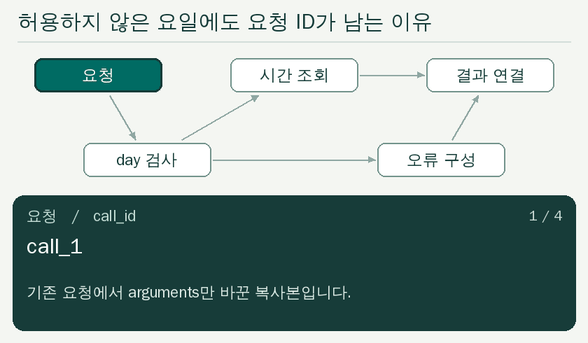

day가 Friday인 요청은 조회 함수를 실행하기 전에 걸러집니다. 결과의 ok는 False이지만 바깥 call_id에는 원래 요청 ID가 남습니다.


### 과제 03 · call_id 일치 여부

원본 call과 결과 reply의 ID가 같은지 확인하고, 같으면 그 ID를 출력하세요.


In [3]:
# 두 ID가 같은지 검사하세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>assert reply[&quot;call_id&quot;] == call[&quot;call_id&quot;]
print(reply[&quot;call_id&quot;])</code></pre>
<p>실행 결과</p><pre><code>call_1</code></pre>
<p>call_1입니다. 모델에게 다음 답변을 요청할 때는 사용자 질문과 호출 항목 다음에 이 결과를 넣습니다.</p>
</details>


### function_call_output의 두 층

<p>reply의 call_id는 바깥 딕셔너리에서 바로 읽습니다. 반면 output에는 성공 여부와 조회 데이터가 JSON 문자열로 들어 있습니다. json.loads(reply['output'])을 거치면 data에서 hours를 꺼낼 수 있습니다.</p>


### 셀 04 · 허용 목록 밖 인자 거부

이번 요청의 ID는 유효하나 day가 명세의 두 선택지 밖에 있습니다.


In [4]:
bad = {**call, "arguments": '{"day":"Friday"}'}
rejected = execute_call(bad)
print(json.loads(rejected["output"]))

{'ok': False, 'error': 'invalid_tool_request'}


ok가 False이고 error가 invalid_tool_request입니다. 허용되지 않은 요일로 얻은 시간을 사용자에게 보여 주는 일을 막았습니다.


### 오류 결과의 전달

<table><caption>실패 사례</caption><thead><tr><th scope="col">입력</th><th scope="col">예상 처리</th></tr>
</thead><tbody><tr><td>등록하지 않은 함수 이름</td><td>오류 결과, 함수 실행 없음</td></tr>
<tr><td>day=holiday</td><td>오류 결과</td></tr>
<tr><td>JSON으로 읽히지 않는 인자</td><td>오류 결과</td></tr>
<tr><td>불필요한 extra 필드</td><td>오류 결과</td></tr>
<tr><td>call_id 누락·공백·문자열 아님</td><td>연결 불가 예외, 도구 실행 없음</td></tr>
<tr><td>완료되지 않은 최종 응답</td><td>성공 반환 대신 예외</td></tr>
</tbody></table>


## 대화 기록에 호출과 결과 추가

도구 호출을 제안한 응답과 함수 실행 결과를 대화 끝에 차례로 넣습니다. 모델에 다시 보내기 직전에는 결과가 어느 항목인지, 조회 실패를 개관 시간으로 오해하지 않았는지 살펴보세요.

### 호출 요청 한 건이 답변에 쓰이기까지

**주말 운영 시간을 요청합니다.**　이 시점에는 조회할 함수와 요일만 정해졌습니다.

```
call_id = call_1
get_library_hours(day="weekend")
```

**시간표에서 주말 항목을 찾습니다.**　함수를 호출한 프로그램이 결과를 받았습니다. 요청을 받기만 한 상태에서는 이 값을 알 수 없습니다.

```
hours = 10:00~16:00
```

**조회 결과에 같은 ID를 붙입니다.**　function_call_output과 원래 요청이 call_1로 이어집니다. 대화 목록에서 서로 이웃하는지만 보고 연결하면 호출 두 개의 결과가 뒤바뀔 수 있습니다.

```
type = function_call_output
call_id = call_1
운영 시간 = 10:00~16:00
```

**결과에서 시간을 읽어 안내합니다.**　이 장의 풀이에서는 저장한 결과로 안내 문장을 만듭니다.

```
가상 주말 운영 시간: 10:00~16:00
```


### 질문 뒤에 호출 항목과 결과 붙이기

<p>history에는 사용자 질문, 모델의 호출 요청, 프로그램이 만든 결과가 차례대로 들어갑니다. 마지막 항목에서 function_call_output을 읽고 같은 call_id의 이전 요청을 찾아 연결해 보세요.</p>


### 셀 05 · append()로 호출 이력 구성

대화 내역을 만든 뒤 마지막 항목의 유형을 읽습니다.


In [5]:
history = [{"role": "user", "content": "주말 운영 시간은?"}]
history.append(call)
history.append(reply)
print(history[-1]["type"])

function_call_output


function_call_output이 나옵니다. 모델의 최종 메시지는 아직 없습니다. 다음 과제에서는 조회 값으로 안내 문장을 직접 만듭니다.


### 도구 왕복의 모델·프로그램 역할

<p>모델이 get_library_hours와 day=weekend를 요청하면 Python 코드가 이름과 인자를 검사합니다. 조건에 맞으면 Python 함수가 실제로 실행되고 결과를 JSON 문자열로 바꿉니다. 이후 모델이 그 결과를 받아 답변을 작성합니다.</p>

<p>여기서 실제로 실행되는 함수는 교육용 정적 시간표를 반환합니다. 실제 도서관 서버나 예약 시스템에 접속하지 않습니다. 기본 모델 응답은 모의 자료지만 도구 함수 실행과 메시지 연결 코드는 실제로 실행합니다.</p>

<h3>실행하기 전에 걸러지는 요청</h3>

<p>함수 호출 전에 이름과 요일을 확인합니다. 허용된 요청만 3단계로 계속합니다.</p>

<article><small>STEP 01 · 모델</small><h4>함수 이름과 인자 제안</h4>
<p>호출 ID와 함께 도구를 요청합니다.</p><pre>function_call</pre></article>

<article><small>STEP 02 · Python</small><h4>도구 허용 목록과 인자 검사</h4>
<p>조건이 틀리면 오류 결과를 만듭니다.</p><pre>weekday 또는 weekend → 조회로 이동
그 밖의 값 → 검사 실패, 조회 0회</pre></article>

<article><small>STEP 03 · Python 함수</small><h4>시간표 함수 실행</h4>
<p>읽기 전용 딕셔너리를 조회합니다.</p><pre>hours</pre></article>

<article><small>STEP 04 · Python → 모델</small><h4>호출 ID별 결과 반환</h4>
<p>도구 결과를 받은 뒤 최종 답변을 요청합니다.</p><pre>function_call_output</pre></article>


### 과제 06 · 도구 출력에서 최종 답변 조립

현재 대화의 마지막 항목을 읽어 성공한 결과일 때만 시간을 넣어 안내하세요. 이 문장은 실제 모델 답변 대신 쓰는 연습용 문구입니다.


In [6]:
# history에서 성공 여부와 시간을 읽으세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>payload = json.loads(history[-1][&quot;output&quot;])
if payload[&quot;ok&quot;]:
    print(&quot;가상 주말 운영 시간:&quot;, payload[&quot;data&quot;][&quot;hours&quot;])
else:
    print(&quot;운영 시간을 확인하지 못했습니다.&quot;)</code></pre>
<p>실행 결과</p><pre><code>가상 주말 운영 시간: 10:00~16:00</code></pre>
<p>예제에서는 ‘가상 주말 운영 시간: 10:00~16:00’이 나옵니다. 한 번의 왕복에서 도구 실행은 한 번이고, 실제 SDK를 쓰는 구성이라면 최초 요청과 최종 답 요청을 따로 셉니다.</p>
</details>


### 파이썬 함수의 실제 반환값 확인

<p>get_library_hours('weekend')는 이 노트북의 가상 시간표를 조회합니다. 10:00~16:00은 함수가 읽어 낸 값입니다. 마지막 셀에서는 이 값을 사용해 한국어 문장을 조립합니다.</p>


## 돌아보기

요청 ID, 도구 반환값, 사용자에게 보여 줄 문장 중 하나가 비어 있는 대화를 상상해 보세요. 어느 단계에서 멈춰야 하는지 설명할 수 있으면 다음 장의 여러 번 왕복도 한 번씩 읽을 수 있습니다.

### 실행하기 전에 걸러지는 요청

**함수 이름·인자 제안**　호출 ID와 함께 도구를 요청합니다.

```
function_call
```

**허용 목록·필드 확인**　조건이 틀리면 오류 결과를 만듭니다.

```
weekday 또는 weekend → 조회로 이동
그 밖의 값 → 검사 실패, 조회 0회
```

**가상 운영 시간 조회**　읽기 전용 딕셔너리를 조회합니다.

```
hours
```

**동일 ID로 결과 전달**　도구 결과를 받은 뒤 최종 답변을 요청합니다.

```
function_call_output
```


### 단일 도구 왕복 구현

<p>다음 장에서는 이 왕복을 반복하되 호출 상한과 종료 조건을 둡니다.</p>
